# Fine-tune DTLN cho VIVOS và so sánh với pretrained — ASR fix v2

Chạy trên **Colab GPU**. Notebook dùng hai ZIP đã tạo:

- `dataset/dtln_exports/vivos_dtln_4s_v1.zip`: 20.000 train + 2.000 validation.
- `dataset/dtln_exports/vivos_dtln_test_v1.zip`: `test_4s` + `test_utterance`.

Khởi tạo từ **DTLN norm pretrained 500 giờ** chính thức. Tất cả layer được fine-tune
với learning rate 1e-4; checkpoint tốt nhất được chọn **chỉ bằng validation**.
So sánh noisy / pretrained / fine-tuned trên cùng test bằng PESQ-WB, STOI, SI-SDR, SNR;
có thêm WER/CER bằng PhoWhisper khi bật `RUN_ASR`.

**Lần đầu:** giữ `SMOKE_TEST=True` để thử 1 epoch. Khi mọi cell chạy xong, đổi
`SMOKE_TEST=False` rồi Run all. Smoke và full dùng thư mục riêng. Các ZIP nguồn
được dùng lại; không tải hay trộn lại các bộ âm thanh gốc.

Model pretrained, model fine-tuned, checkpoint mỗi epoch và báo cáo đều lưu ở
`MyDrive/dataset/dtln_models/dtln_vivos_ft_v1/` (smoke có hậu tố `-smoke`).
Notebook tạo ra quy trình huấn luyện; số đo thật chỉ xuất hiện sau khi chạy Colab.


In [3]:
#@title 1. Gắn Drive và chuẩn bị thư viện
from google.colab import drive
drive.mount('/content/drive')
import os, sys, subprocess, importlib.util
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('CC', 'gcc')
# Dùng TensorFlow GPU có sẵn của Colab, tránh thay đổi bộ CUDA đang hoạt động.
if importlib.util.find_spec('tensorflow') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'tensorflow==2.19.1'])
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
    'soundfile>=0.12', 'pystoi==0.4.1', 'pesq==0.0.4', 'pandas', 'matplotlib', 'tqdm'])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


0

In [4]:
#@title 2. Cấu hình lần chạy (chạy thử trước, sau đó đổi SMOKE_TEST = False)
from pathlib import Path

DRIVE_DATA = Path('/content/drive/MyDrive/dataset')
TRAINVAL_ZIP = DRIVE_DATA / 'dtln_exports/vivos_dtln_4s_v1.zip'
TEST_ZIP = DRIVE_DATA / 'dtln_exports/vivos_dtln_test_v1.zip'
RUN_NAME = 'dtln_vivos_ft_v1'
OUTPUT_BASE = DRIVE_DATA / 'dtln_models'
SMOKE_TEST = False  # 1 epoch, 64 train, 32 val, 10 test; bản thật lưu ở run riêng.
RESUME = True
REQUIRE_GPU = True

BATCH_SIZE = 8  # Nếu hết VRAM, giảm 4 hoặc 2 rồi dùng RUN_NAME mới.
LEARNING_RATE = 1e-4
MAX_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 7
SEED = 42
EVAL_BATCH_SIZE = 8
EVALUATE_UTTERANCES = True
SAVE_ENHANCED = True  # Lưu cả WAV của hai model vào ZIP kết quả trên Drive.
RUN_ASR = True  # Tùy chọn WER/CER với PhoWhisper, chạy thêm lâu hơn.
ASR_MODEL = 'vinai/PhoWhisper-small'

SR, N, PAD = 16_000, 64_000, 384
UPSTREAM_COMMIT = '1de1f15a8b5b7e1c44905618ff2ef70ca8277fbc'
PRETRAIN_FILENAME = 'DTLN_norm_500h.h5'
LOCAL_WORK = Path('/content/dtln_finetune_work')
RUN_DIR = OUTPUT_BASE / (RUN_NAME + ('-smoke' if SMOKE_TEST else ''))
RUN_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_WORK.mkdir(parents=True, exist_ok=True)
print('Kết quả lưu tại:', RUN_DIR)


Kết quả lưu tại: /content/drive/MyDrive/dataset/dtln_models/dtln_vivos_ft_v1


ZIP được giải nén vào đĩa Colab để đọc nhanh. Sau khi mất runtime phải giải nén
lại, nhưng checkpoint và model trên Drive vẫn còn. Kiểm tra tên cặp, định dạng,
manifest, người nói và môi trường DEMAND tách biệt trước khi huấn luyện.

In [5]:
#@title 3. Giải nén ZIP và kiểm tra dữ liệu
import csv
import hashlib
import itertools
import json
import math
import os
import shutil
import stat
import tempfile
import zipfile
from pathlib import PurePosixPath

import numpy as np
import pandas as pd
import soundfile as sf
from tqdm.auto import tqdm


def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(8 * 1024**2), b''):
            h.update(block)
    return h.hexdigest()


def atomic_json(path, value):
    path = Path(path)
    tmp = path.with_name(path.name + '.tmp')
    tmp.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    os.replace(tmp, path)


def extract_cached(archive, label):
    archive = Path(archive)
    if not archive.is_file():
        raise FileNotFoundError(f'Thiếu {archive}; sửa đường dẫn ở cell cấu hình.')
    identity = {'path': str(archive), 'size': archive.stat().st_size,
                'mtime': archive.stat().st_mtime_ns}
    key = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:12]
    out = LOCAL_WORK / f'{label}-{key}'
    if (out / '.complete.json').is_file():
        return out, identity
    with zipfile.ZipFile(archive) as z:
        members = z.infolist()
        need = sum(x.file_size for x in members)
        if shutil.disk_usage(LOCAL_WORK).free < need + 1024**3:
            raise OSError(f'Cần thêm khoảng {need / 1e9:.2f} GB đĩa Colab để giải nén {archive.name}.')
        with tempfile.TemporaryDirectory(prefix=f'.{label}-', dir=LOCAL_WORK) as tmp:
            staging = Path(tmp) / 'data'
            staging.mkdir()
            for entry in tqdm(members, desc=f'Giải nén {label}'):
                p = PurePosixPath(entry.filename.replace('\\', '/'))
                if p.is_absolute() or '..' in p.parts or (p.parts and ':' in p.parts[0]):
                    raise ValueError(f'Đường dẫn ZIP không hợp lệ: {entry.filename}')
                if stat.S_ISLNK(entry.external_attr >> 16):
                    raise ValueError('Không chấp nhận symlink trong ZIP dữ liệu.')
                if entry.is_dir():
                    continue
                dst = staging.joinpath(*p.parts)
                dst.parent.mkdir(parents=True, exist_ok=True)
                with z.open(entry) as src, dst.open('wb') as f:
                    shutil.copyfileobj(src, f, 1024**2)
            atomic_json(staging / '.complete.json', identity)
            staging.rename(out)
    return out, identity


def find_root(folder, required):
    candidates = [p for p in (folder, *folder.iterdir()) if p.is_dir()
                  and all((p / r).exists() for r in required)]
    if len(candidates) != 1:
        raise ValueError(f'Cần đúng một thư mục có {required} dưới {folder}; có {len(candidates)}.')
    return candidates[0]


def read_pairs(folder, fixed_frames=None):
    noisy = {p.name: p for p in (folder / 'noisy').glob('*.wav')}
    clean = {p.name: p for p in (folder / 'clean').glob('*.wav')}
    if not noisy or noisy.keys() != clean.keys():
        raise ValueError(f'{folder}: clean/noisy rỗng hoặc tên không khớp.')
    pairs = []
    for name in tqdm(sorted(noisy), desc=f'Kiểm tra {folder.name}'):
        a, b = sf.info(noisy[name]), sf.info(clean[name])
        if any(i.samplerate != SR or i.channels != 1 or i.subtype != 'PCM_16' for i in (a, b)):
            raise ValueError(f'{name}: yêu cầu mono 16kHz PCM16.')
        if a.frames != b.frames or a.frames <= 0 or (fixed_frames and a.frames != fixed_frames):
            raise ValueError(f'{name}: số mẫu không hợp lệ/không khớp.')
        pairs.append((noisy[name], clean[name]))
    return pairs


train_staged, TRAIN_ARCHIVE_ID = extract_cached(TRAINVAL_ZIP, 'trainval')
test_staged, TEST_ARCHIVE_ID = extract_cached(TEST_ZIP, 'test')
TRAIN_ROOT = find_root(train_staged, ['train/noisy', 'val/noisy', 'manifest.csv'])
TEST_ROOT = find_root(test_staged, ['test_4s/noisy', 'manifest_4s.csv'])
TRAIN_PAIRS = read_pairs(TRAIN_ROOT / 'train', N)
VAL_PAIRS = read_pairs(TRAIN_ROOT / 'val', N)
TEST_PAIRS_ALL = read_pairs(TEST_ROOT / 'test_4s', N)
UTTERANCE_PAIRS_ALL = read_pairs(TEST_ROOT / 'test_utterance') if EVALUATE_UTTERANCES else []
TRAIN_MANIFEST = pd.read_csv(TRAIN_ROOT / 'manifest.csv', keep_default_na=False)
TEST_MANIFEST = pd.read_csv(TEST_ROOT / 'manifest_4s.csv', keep_default_na=False)
UTT_MANIFEST = (pd.read_csv(TEST_ROOT / 'manifest_utterance.csv', keep_default_na=False)
                if EVALUATE_UTTERANCES else pd.DataFrame())


def validate_manifest(frame, pairs, label):
    if frame['filename'].duplicated().any() or set(frame['filename']) != {a.name for a, _ in pairs}:
        raise ValueError(f'{label}: manifest không khớp WAV hoặc trùng tên.')


for split, pairs in [('train', TRAIN_PAIRS), ('val', VAL_PAIRS)]:
    validate_manifest(TRAIN_MANIFEST[TRAIN_MANIFEST['split'] == split], pairs, split)
validate_manifest(TEST_MANIFEST, TEST_PAIRS_ALL, 'test_4s')
if EVALUATE_UTTERANCES:
    validate_manifest(UTT_MANIFEST, UTTERANCE_PAIRS_ALL, 'test_utterance')

# Kiểm tra người nói và DEMAND theo manifest nguồn, trước khi chọn mẫu smoke.
speakers = {}
for split in ['train', 'val']:
    rows = TRAIN_MANIFEST[TRAIN_MANIFEST['split'] == split]
    speakers[split] = {s for value in rows['speakers'] for s in json.loads(value)}
speakers['test'] = set(TEST_MANIFEST['speaker'])
for a, b in itertools.combinations(speakers, 2):
    if speakers[a] & speakers[b]:
        raise ValueError(f'Người nói trùng {a}/{b}: {speakers[a] & speakers[b]}')

source_index = pd.read_csv(TRAIN_ROOT / 'source_index.csv', keep_default_na=False)
old_envs = {PurePosixPath(x).parent.name for x in source_index.loc[source_index['kind'] == 'demand', 'path']}
test_envs = set(TEST_MANIFEST['noise_environment'])
if old_envs & test_envs:
    raise ValueError(f'DEMAND test trùng train/val: {old_envs & test_envs}')
if test_envs != {'NFIELD', 'OHALLWAY'}:
    raise ValueError(f'Kiểm tra lại noise test: {test_envs}')

if SMOKE_TEST:
    TRAIN_PAIRS, VAL_PAIRS = TRAIN_PAIRS[:64], VAL_PAIRS[:32]
    # Lấy đúng một cặp cho mỗi tổ hợp SNR/môi trường trong smoke.
    chosen = TEST_MANIFEST.groupby(['snr_db', 'noise_environment'], sort=True).head(1)
    names = set(chosen['filename'])
    TEST_PAIRS = [p for p in TEST_PAIRS_ALL if p[0].name in names]
    UTTERANCE_PAIRS = UTTERANCE_PAIRS_ALL[:10]
else:
    TEST_PAIRS, UTTERANCE_PAIRS = TEST_PAIRS_ALL, UTTERANCE_PAIRS_ALL
print('Số cặp sẽ dùng:', {k: len(v) for k, v in [('train', TRAIN_PAIRS), ('val', VAL_PAIRS),
      ('test_4s', TEST_PAIRS), ('test_utterance', UTTERANCE_PAIRS)]})


Giải nén trainval:   0%|          | 0/44003 [00:00<?, ?it/s]

Giải nén test:   0%|          | 0/5523 [00:00<?, ?it/s]

Kiểm tra train:   0%|          | 0/20000 [00:00<?, ?it/s]

Kiểm tra val:   0%|          | 0/2000 [00:00<?, ?it/s]

Kiểm tra test_4s:   0%|          | 0/2000 [00:00<?, ?it/s]

Kiểm tra test_utterance:   0%|          | 0/760 [00:00<?, ?it/s]

Số cặp sẽ dùng: {'train': 20000, 'val': 2000, 'test_4s': 2000, 'test_utterance': 760}


In [6]:
#@title 4. Định nghĩa DTLN tương thích Keras hiện nay
# Mã kiến trúc được lưu cùng model để load/inference về sau.
MODEL_SOURCE = '"""DTLN norm 500h, compatible with upstream weights and Keras 3.\n\nArchitecture: breizhn/DTLN, MIT license, commit\n1de1f15a8b5b7e1c44905618ff2ef70ca8277fbc.\n"""\nimport numpy as np\nimport tensorflow as tf\nfrom tensorflow import keras\n\nSR, BLOCK, HOP, PAD = 16000, 512, 128, 384\n\n\n@keras.utils.register_keras_serializable(package="DTLN")\nclass STFT(keras.layers.Layer):\n    def call(self, x):\n        z = tf.signal.rfft(tf.signal.frame(x, BLOCK, HOP))\n        return tf.abs(z), tf.math.angle(z)\n\n\n@keras.utils.register_keras_serializable(package="DTLN")\nclass InverseFFT(keras.layers.Layer):\n    def call(self, inputs):\n        mag, phase = inputs\n        z = tf.cast(mag, tf.complex64) * tf.exp(tf.complex(tf.zeros_like(phase), phase))\n        return tf.signal.irfft(z, fft_length=[BLOCK])\n\n\n@keras.utils.register_keras_serializable(package="DTLN")\nclass OverlapAdd(keras.layers.Layer):\n    def call(self, x):\n        return tf.signal.overlap_and_add(x, HOP)\n\n\n@keras.utils.register_keras_serializable(package="DTLN")\nclass LogMagnitude(keras.layers.Layer):\n    def call(self, x):\n        return tf.math.log(x + 1e-7)\n\n\n@keras.utils.register_keras_serializable(package="DTLN")\nclass InstantLayerNormalization(keras.layers.Layer):\n    def build(self, input_shape):\n        self.gamma = self.add_weight(name="gamma", shape=(input_shape[-1],), initializer="ones")\n        self.beta = self.add_weight(name="beta", shape=(input_shape[-1],), initializer="zeros")\n\n    def call(self, x):\n        mean = tf.reduce_mean(x, axis=-1, keepdims=True)\n        var = tf.reduce_mean(tf.square(x - mean), axis=-1, keepdims=True)\n        return (x - mean) / tf.sqrt(var + 1e-7) * self.gamma + self.beta\n\n\ndef build_dtln():\n    x = keras.Input(shape=(None,), name="audio_16k")\n    mag, phase = STFT(name="stft")(x)\n    z = InstantLayerNormalization(name="stft_norm")(LogMagnitude(name="log_mag")(mag))\n    for i in range(2):\n        z = keras.layers.LSTM(128, return_sequences=True, name=f"stage1_lstm{i+1}")(z)\n        if i == 0:\n            z = keras.layers.Dropout(0.25, name="stage1_dropout")(z)\n    mask = keras.layers.Dense(257, name="stage1_dense")(z)\n    mask = keras.layers.Activation("sigmoid", name="stage1_mask")(mask)\n    z = InverseFFT(name="ifft")([keras.layers.Multiply()([mag, mask]), phase])\n    encoded = keras.layers.Conv1D(256, 1, use_bias=False, name="encoder")(z)\n    z = InstantLayerNormalization(name="encoder_norm")(encoded)\n    for i in range(2):\n        z = keras.layers.LSTM(128, return_sequences=True, name=f"stage2_lstm{i+1}")(z)\n        if i == 0:\n            z = keras.layers.Dropout(0.25, name="stage2_dropout")(z)\n    mask = keras.layers.Dense(256, name="stage2_dense")(z)\n    mask = keras.layers.Activation("sigmoid", name="stage2_mask")(mask)\n    z = keras.layers.Multiply()([encoded, mask])\n    z = keras.layers.Conv1D(BLOCK, 1, padding="causal", use_bias=False, name="decoder")(z)\n    return keras.Model(x, OverlapAdd(name="overlap_add")(z), name="DTLN_norm_500h")\n\n\n@keras.utils.register_keras_serializable(package="DTLN")\ndef snr_loss(y_true, y_pred):\n    # Input to model has PAD zeros each side; score only the original clean samples.\n    pred = y_pred[:, PAD:PAD + tf.shape(y_true)[-1]]\n    power = tf.reduce_mean(tf.square(y_true), axis=-1)\n    error = tf.reduce_mean(tf.square(y_true - pred), axis=-1)\n    return -10.0 * tf.math.log((power + 1e-7) / (error + 1e-7)) / tf.math.log(10.0)\n\n\ndef enhance(model, audio):\n    """Mono float32 16-kHz waveform -> same-length waveform, no gain normalization."""\n    x = np.asarray(audio, dtype=np.float32)\n    if x.ndim != 1 or not len(x) or not np.isfinite(x).all():\n        raise ValueError("Expected finite, nonempty mono waveform")\n    padded = np.pad(x, (PAD, PAD + (-len(x)) % HOP))\n    y = model(padded[None, :], training=False).numpy()[0, PAD:PAD + len(x)]\n    if len(y) != len(x) or not np.isfinite(y).all():\n        raise RuntimeError("Invalid DTLN output")\n    return y.astype(np.float32)\n'
Path('/content/dtln_colab_model.py').write_text(MODEL_SOURCE, encoding='utf-8')
import sys
if '/content' not in sys.path: sys.path.insert(0, '/content')


In [7]:
#@title 5. Tải pretrained chính thức và chuẩn bị fine-tune
import importlib
import urllib.request
import tensorflow as tf
from tensorflow import keras
from dtln_colab_model import build_dtln, snr_loss, enhance

keras.utils.set_random_seed(SEED)
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
if REQUIRE_GPU and not gpus:
    raise RuntimeError('Chọn Runtime > Change runtime type > GPU, rồi chạy lại. Có thể đặt REQUIRE_GPU=False để thử CPU.')
print('TensorFlow:', tf.__version__, '| GPU:', gpus)

PRE_DIR = RUN_DIR / 'pretrained'
FT_DIR = RUN_DIR / 'finetuned'
CODE_DIR = RUN_DIR / 'code'
EVAL_DIR = RUN_DIR / 'evaluation'
for folder in [PRE_DIR, FT_DIR, CODE_DIR, EVAL_DIR, RUN_DIR / 'checkpoints']:
    folder.mkdir(parents=True, exist_ok=True)

base_url = f'https://raw.githubusercontent.com/breizhn/DTLN/{UPSTREAM_COMMIT}'
ORIGINAL_WEIGHTS = PRE_DIR / PRETRAIN_FILENAME
expected_sha = '378c209ad3f4dedffb185b542169a51472361a23492c13b377feb2485a2a1bb3'
if not ORIGINAL_WEIGHTS.exists():
    tmp = ORIGINAL_WEIGHTS.with_suffix('.h5.part')
    urllib.request.urlretrieve(f'{base_url}/pretrained_model/{PRETRAIN_FILENAME}', tmp)
    if sha256_file(tmp) != expected_sha:
        raise ValueError('Checksum pretrained không khớp nguồn đã kiểm tra.')
    os.replace(tmp, ORIGINAL_WEIGHTS)
if sha256_file(ORIGINAL_WEIGHTS) != expected_sha:
    raise ValueError('Tệp pretrained trên Drive đã thay đổi; không tiếp tục.')
for source in ['LICENSE', 'DTLN_model.py']:
    target = CODE_DIR / ('upstream_' + source)
    if not target.exists():
        urllib.request.urlretrieve(f'{base_url}/{source}', target)
shutil.copy2('/content/dtln_colab_model.py', CODE_DIR / 'dtln_colab_model.py')

pretrained_model = build_dtln()
pretrained_model.load_weights(ORIGINAL_WEIGHTS)  # load theo topology; tuyệt đối không skip_mismatch.
if not (PRE_DIR / 'dtln_pretrained.keras').exists():
    pretrained_model.save(PRE_DIR / 'dtln_pretrained.keras')
    pretrained_model.save_weights(PRE_DIR / 'dtln_pretrained.weights.h5')

run_config = {
    'architecture': 'DTLN_norm_500h', 'upstream_commit': UPSTREAM_COMMIT,
    'pretrained_sha256': expected_sha, 'tensorflow': tf.__version__,
    'seed': SEED, 'batch_size': BATCH_SIZE, 'learning_rate': LEARNING_RATE,
    'max_epochs': MAX_EPOCHS, 'smoke_test': SMOKE_TEST, 'sample_rate': SR,
    'frames': N, 'pad': PAD, 'train_archive': TRAIN_ARCHIVE_ID, 'test_archive': TEST_ARCHIVE_ID,
    'train_manifest_sha256': sha256_file(TRAIN_ROOT / 'manifest.csv'),
    'test_manifest_sha256': sha256_file(TEST_ROOT / 'manifest_4s.csv'),
    'counts': {'train': len(TRAIN_PAIRS), 'val': len(VAL_PAIRS), 'test_4s': len(TEST_PAIRS)},
}
identity_config = {k: v for k, v in run_config.items() if k not in ['max_epochs']}
CONFIG_PATH = RUN_DIR / 'run_config.json'
if CONFIG_PATH.exists():
    old = json.loads(CONFIG_PATH.read_text())
    if {k: v for k, v in old.items() if k != 'max_epochs'} != identity_config:
        raise ValueError('Cấu hình/dữ liệu khác lần trước. Đổi RUN_NAME để tránh trộn checkpoint.')
atomic_json(CONFIG_PATH, run_config)

STATE_PATH = RUN_DIR / 'training_state.json'
state = json.loads(STATE_PATH.read_text()) if RESUME and STATE_PATH.exists() else {'epochs': []}
if STATE_PATH.exists() and not RESUME:
    raise FileExistsError('Run đã có checkpoint. Bật RESUME hoặc dùng RUN_NAME mới.')
if state['epochs']:
    training_model = keras.models.load_model(RUN_DIR / state['epochs'][-1]['checkpoint'])
    INITIAL_EPOCH = int(state['epochs'][-1]['epoch'])
    print('Tiếp tục sau epoch', INITIAL_EPOCH, '(đã phục hồi optimizer).')
else:
    training_model = build_dtln()
    training_model.set_weights(pretrained_model.get_weights())
    training_model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=3.0),
                           loss=snr_loss, jit_compile=False)
    INITIAL_EPOCH = 0
training_model.summary()


TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Tiếp tục sau epoch 30 (đã phục hồi optimizer).


Model: "DTLN_norm_500h"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ audio_16k           │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stft (STFT)         │ [(None, None,     │          0 │ audio_16k[0][0]   │
│                     │ 257), (None,      │            │                   │
│                     │ None, 257)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ log_mag             │ (None, None, 257) │          0 │ stft[0][0]        │
│ (LogMagnitude)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stft_norm           │ (None, None, 257) │        514 │ log_mag[0][0]     │
│ (InstantLayerNorma… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_lstm1 (LSTM) │ (None, None, 128) │    197,632 │ stft_norm[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_dropout      │ (None, None, 128) │          0 │ stage1_lstm1[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_lstm2 (LSTM) │ (None, None, 128) │    131,584 │ stage1_dropout[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_dense        │ (None, None, 257) │     33,153 │ stage1_lstm2[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_mask         │ (None, None, 257) │          0 │ stage1_dense[0][… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_6          │ (None, None, 257) │          0 │ stft[0][0],       │
│ (Multiply)          │                   │            │ stage1_mask[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ifft (InverseFFT)   │ (None, None, 512) │          0 │ multiply_6[0][0], │
│                     │                   │            │ stft[0][1]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder (Conv1D)    │ (None, None, 256) │    131,072 │ ifft[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_norm        │ (None, None, 256) │        512 │ encoder[0][0]     │
│ (InstantLayerNorma… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage2_lstm1 (LSTM) │ (None, None, 128) │    197,120 │ encoder_norm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage2_dropout      │ (None, None, 128) │          0 │ stage2_lstm1[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage2_lstm2 (LSTM) │ (None, None, 128) │    131,584 │ stage2_dropout[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage2_dense        │ (None, None, 256) │     33,024 │ stage2_lstm2[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage2_mask         │ (None, None, 256) │          0 │ stage2_dense[0][… │
│ (Activation)        │                   │            │                 

 Total params: 2,961,803 (11.30 MB)

 Trainable params: 987,267 (3.77 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,974,536 (7.53 MB)

## Huấn luyện và tiếp tục sau khi ngắt

Đặt `RESUME=True`, giữ `RUN_NAME`/cấu hình/dữ liệu rồi Run all để tiếp tục từ epoch
đã lưu. Cả optimizer cũng được phục hồi; epoch đang dở chạy lại. Patience của
EarlyStopping/ReduceLROnPlateau đếm lại khi mở phiên mới. Dùng run mới nếu đổi batch size,
learning rate hay dữ liệu. Có thể tăng `MAX_EPOCHS` để huấn luyện tiếp.

4 giây là đúng 64.000 mẫu; không dùng generator gốc mặc định 15 giây. Input được
zero-pad 384 mẫu hai đầu; loss chỉ tính trên 64.000 mẫu gốc, cùng cách padding inference.


Đã đủ số epoch; dùng checkpoint đã lưu.
Best epoch: 25 | val_loss: -16.436939239501953


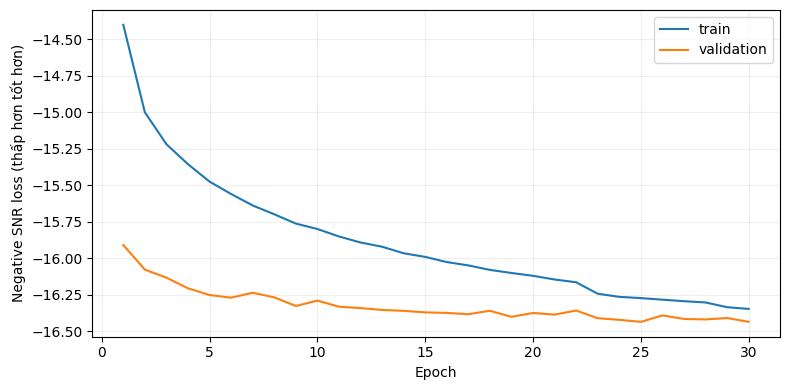

14187

In [8]:
#@title 6. Fine-tune; lưu checkpoint lên Drive sau mỗi epoch

def make_tf_dataset(pairs, training):
    paths_a = [str(a) for a, b in pairs]
    paths_b = [str(b) for a, b in pairs]
    ds = tf.data.Dataset.from_tensor_slices((paths_a, paths_b))
    if training:
        ds = ds.shuffle(min(len(pairs), 20000), seed=SEED, reshuffle_each_iteration=True)

    def decode(noisy_path, clean_path):
        noisy, sr_a = tf.audio.decode_wav(tf.io.read_file(noisy_path))
        clean, sr_b = tf.audio.decode_wav(tf.io.read_file(clean_path))
        tf.debugging.assert_equal(sr_a, SR)
        tf.debugging.assert_equal(sr_b, SR)
        noisy = tf.ensure_shape(noisy, (N, 1))[:, 0]
        clean = tf.ensure_shape(clean, (N, 1))[:, 0]
        return tf.pad(noisy, [[PAD, PAD]]), clean

    # Một số Colab giới hạn thread; không tạo pool đọc quá lớn.
    ds = ds.map(decode, num_parallel_calls=4)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 4
    options.threading.max_intra_op_parallelism = 1
    return ds.batch(BATCH_SIZE, drop_remainder=False).with_options(options).prefetch(2)


class DriveCheckpoint(keras.callbacks.Callback):
    def __init__(self, saved_state):
        super().__init__()
        self.saved_state = saved_state

    def on_epoch_end(self, epoch, logs=None):
        logs = {k: float(v) for k, v in (logs or {}).items()}
        if not all(np.isfinite(v) for v in logs.values()):
            raise RuntimeError('Loss không hữu hạn; không ghi đè checkpoint hợp lệ.')
        relative = f'checkpoints/epoch_{epoch+1:04d}.keras'
        final = RUN_DIR / relative
        tmp = final.with_name(f'.epoch_{epoch+1:04d}.keras')
        self.model.save(tmp)  # Bao gồm optimizer để tiếp tục fine-tune.
        os.replace(tmp, final)
        record = {'epoch': epoch + 1, 'checkpoint': relative, **logs}
        self.saved_state['epochs'].append(record)
        atomic_json(STATE_PATH, self.saved_state)
        pd.DataFrame(self.saved_state['epochs']).to_csv(RUN_DIR / 'history.csv', index=False)
        print(f'\nĐã lưu epoch {epoch+1} lên Drive: {final.name}')


TRAIN_DS = make_tf_dataset(TRAIN_PAIRS, True)
VAL_DS = make_tf_dataset(VAL_PAIRS, False)
TARGET_EPOCHS = 1 if SMOKE_TEST else MAX_EPOCHS
callbacks = [
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=EARLY_STOPPING_PATIENCE, verbose=1,
                                  restore_best_weights=False),
    DriveCheckpoint(state),
]
if INITIAL_EPOCH < TARGET_EPOCHS and state.get('completed_target_epochs', 0) < TARGET_EPOCHS:
    training_model.fit(TRAIN_DS, validation_data=VAL_DS, epochs=TARGET_EPOCHS,
                       initial_epoch=INITIAL_EPOCH, callbacks=callbacks, verbose=1)
    state['completed_target_epochs'] = TARGET_EPOCHS
    atomic_json(STATE_PATH, state)
else:
    print('Đã đủ số epoch; dùng checkpoint đã lưu.')

# Chỉ validation quyết định best, kể cả các epoch của phiên Colab trước.
state = json.loads(STATE_PATH.read_text())
best_record = min(state['epochs'], key=lambda r: r['val_loss'])
best_path = RUN_DIR / best_record['checkpoint']
finetuned_model = keras.models.load_model(best_path, compile=False)
tmp_best = FT_DIR / '.dtln_finetuned_best.keras'
finetuned_model.save(tmp_best)
os.replace(tmp_best, FT_DIR / 'dtln_finetuned_best.keras')
finetuned_model.save_weights(FT_DIR / 'dtln_finetuned_best.weights.h5')
atomic_json(FT_DIR / 'best_checkpoint.json', best_record)
print('Best epoch:', best_record['epoch'], '| val_loss:', best_record['val_loss'])

import matplotlib.pyplot as plt
history = pd.DataFrame(state['epochs'])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history['epoch'], history['loss'], label='train')
ax.plot(history['epoch'], history['val_loss'], label='validation')
ax.set(xlabel='Epoch', ylabel='Negative SNR loss (thấp hơn tốt hơn)')
ax.legend(); ax.grid(alpha=0.2)
fig.tight_layout(); fig.savefig(RUN_DIR / 'training_curve.png', dpi=150)
plt.show()

# Ghi đầy đủ môi trường cài đặt để tái lập.
import subprocess, sys
(RUN_DIR / 'requirements_freeze.txt').write_text(
    subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True), encoding='utf-8')


## Đánh giá cuối cùng

Test không được đưa vào `fit` hoặc dùng chọn checkpoint. Cả hai model dùng cùng
padding, cùng âm thanh và không căn chỉnh theo ground truth. Không normalize gain
riêng cho mỗi model. Metric được lưu từng file lên Drive, có thể tiếp tục khi ngắt.

Mặc định đánh giá toàn bộ 2.000 cặp 4 giây và các câu nguyên vẹn. PESQ/STOI lỗi được
ghi rõ; báo cáo có số mẫu hợp lệ. Delta `finetuned - pretrained` dương là cải thiện.
Đánh giá trên hai môi trường DEMAND là phép thử cụ thể, không đại diện mọi loại nhiễu.


test_4s/noisy: 0it [00:00, ?it/s]

test_4s/pretrained:   0%|          | 0/250 [00:00<?, ?it/s]

test_4s/finetuned:   0%|          | 0/250 [00:00<?, ?it/s]

test_utterance/noisy: 0it [00:00, ?it/s]

test_utterance/pretrained:   0%|          | 0/95 [00:00<?, ?it/s]

test_utterance/finetuned:   0%|          | 0/95 [00:00<?, ?it/s]

Tất cả metric dưới đây: cao hơn tốt hơn. STOI nằm trong [0,1].


pesq_wb_mean  pesq_wb_std  pesq_wb_count  \
subset         condition                                              
test_4s        finetuned       2.787319     0.604855           2000   
               noisy           2.206782     0.868249           2000   
               pretrained      2.674172     0.612522           2000   
test_utterance finetuned       2.765574     0.594769            760   
               noisy           2.165354     0.841678            760   
               pretrained      2.646935     0.590086            760   

                           stoi_mean  stoi_std  stoi_count  si_sdr_db_mean  \
subset         condition                                                     
test_4s        finetuned    0.961113  0.051664        2000       19.022498   
               noisy        0.946632  0.064717        2000        5.001552   
               pretrained   0.957648  0.054348        2000       17.403698   
test_utterance finetuned    0.957604  0.051092         760       18.777344   
               noisy        0.942336  0.065631         760        5.003635   
               pretrained   0.953333  0.054510         760       17.196770   

                           si_sdr_db_std  si_sdr_db_count  snr_db_mean  \
subset         condition                                                 
test_4s        finetuned        5.861779             2000    19.147102   
               noisy            7.072399             2000     4.999950   
               pretrained       5.895486             2000    17.565039   
test_utterance finetuned        5.580396              760    18.897163   
               noisy            7.072198              760     4.999952   
               pretrained       5.875877              760    17.367126   

                           snr_db_std  snr_db_count  
subset         condition                             
test_4s        finetuned     5.681418          2000  
               noisy         7.072796          2000  
               pretrained    5.675233          2000  
test_utterance finetuned     5.420518           760  
               noisy         7.075689           760  
               pretrained    5.641731           760

,subset,metric,n_valid_pairs,mean_ft_minus_pretrained,ci95_low,ci95_high
0,test_4s,pesq_wb,2000,0.113146,0.101013,0.124888
1,test_4s,stoi,2000,0.003465,0.003073,0.003847
2,test_4s,si_sdr_db,2000,1.618799,1.485872,1.751565
3,test_4s,snr_db,2000,1.582063,1.449055,1.715651
4,test_utterance,pesq_wb,760,0.118640,0.099911,0.137661
5,test_utterance,stoi,760,0.004271,0.003546,0.004939
6,test_utterance,si_sdr_db,760,1.580574,1.393263,1.783692
7,test_utterance,snr_db,760,1.530036,1.345397,1.731468


CI bootstrap theo file; các file có thể dùng chung câu/noise, không phải mẫu độc lập hoàn toàn.


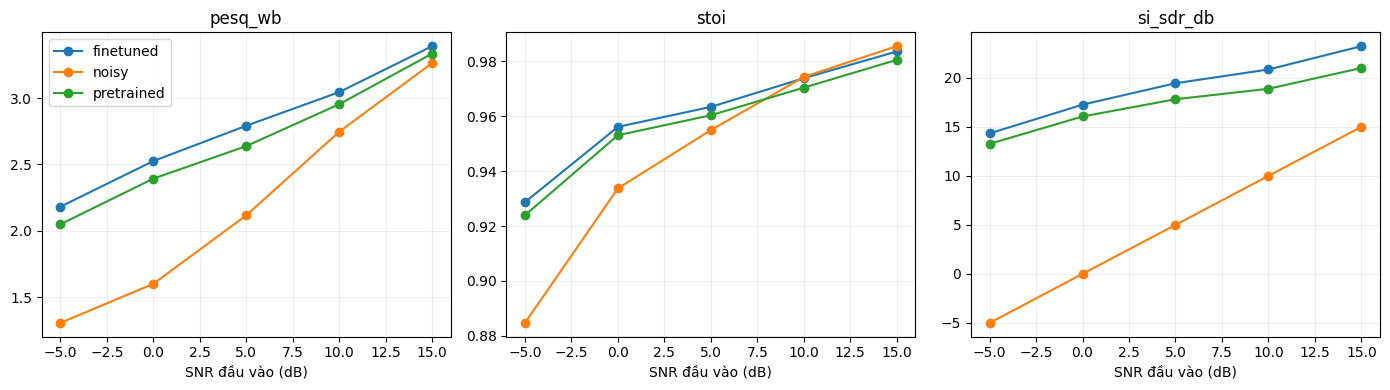

In [9]:
#@title 7. Đánh giá noisy / pretrained / fine-tuned trên cùng tập test
import time
from pesq import pesq
from pystoi import stoi

EVAL_CACHE = LOCAL_WORK / (RUN_DIR.name + '-enhanced')
METRIC_NAMES = ['pesq_wb', 'stoi', 'si_sdr_db', 'snr_db']
FT_SHA = sha256_file(FT_DIR / 'dtln_finetuned_best.weights.h5')
eval_identity = {'pretrained': expected_sha, 'finetuned': FT_SHA,
                 'test_manifest': run_config['test_manifest_sha256'],
                 'smoke': SMOKE_TEST, 'utterances': EVALUATE_UTTERANCES}
eval_id = hashlib.sha256(json.dumps(eval_identity, sort_keys=True).encode()).hexdigest()[:16]
ACTIVE_EVAL = EVAL_DIR / eval_id
ACTIVE_EVAL.mkdir(exist_ok=True)
atomic_json(ACTIVE_EVAL / 'identity.json', eval_identity)
EVAL_CACHE = EVAL_CACHE / eval_id


def read_audio(path):
    x, sr = sf.read(path, dtype='float32')
    if sr != SR or x.ndim != 1 or not np.isfinite(x).all():
        raise ValueError(f'Âm thanh không hợp lệ: {path}')
    return x


def metrics(reference, estimate):
    # Cùng độ dài, không dịch tín hiệu theo target và không chuẩn hóa gain riêng.
    a, b = np.asarray(reference, dtype=np.float64), np.asarray(estimate, dtype=np.float64)
    if a.shape != b.shape or not np.isfinite(b).all():
        raise ValueError('Output không khớp clean hoặc có NaN/Inf.')
    az, bz = a - a.mean(), b - b.mean()
    projection = np.dot(bz, az) / (np.dot(az, az) + 1e-12) * az
    sisdr = 10 * np.log10((np.sum(projection**2) + 1e-12) /
                         (np.sum((bz - projection)**2) + 1e-12))
    snr = 10 * np.log10((np.sum(a**2) + 1e-12) / (np.sum((a-b)**2) + 1e-12))
    result = {'si_sdr_db': float(sisdr), 'snr_db': float(snr)}
    for key, fn in [('pesq_wb', lambda: pesq(SR, a, b, 'wb')),
                    ('stoi', lambda: stoi(a, b, SR, extended=False))]:
        try:
            value = float(fn())
            if not np.isfinite(value):
                raise ValueError('Metric không hữu hạn')
            result[key], result[key + '_error'] = value, ''
        except Exception as exc:
            result[key], result[key + '_error'] = None, f'{type(exc).__name__}: {exc}'
    return result


def enhance_many(model, arrays):
    # Gom các câu có độ dài khác nhau: zero-pad bên phải rồi crop về độ dài gốc.
    padded = [np.pad(a, (PAD, PAD + (-len(a)) % 128)) for a in arrays]
    batch = np.zeros((len(padded), max(map(len, padded))), dtype=np.float32)
    for i, a in enumerate(padded):
        batch[i, :len(a)] = a
    y = model(batch, training=False).numpy()
    return [y[i, PAD:PAD + len(a)].astype(np.float32) for i, a in enumerate(arrays)]


eval_rows = []
models = {'pretrained': pretrained_model, 'finetuned': finetuned_model}
for subset, pairs, manifest in [('test_4s', TEST_PAIRS, TEST_MANIFEST),
                                 ('test_utterance', UTTERANCE_PAIRS, UTT_MANIFEST)]:
    if not pairs:
        continue
    metadata = manifest.set_index('filename').to_dict('index')
    for condition in ['noisy', 'pretrained', 'finetuned']:
        cache_file = ACTIVE_EVAL / f'metrics_{subset}_{condition}.jsonl'
        existing = {}
        if cache_file.exists():
            for line in cache_file.read_text(encoding='utf-8').splitlines():
                try:
                    row = json.loads(line)
                    existing[row['filename']] = row
                except json.JSONDecodeError:
                    # Ghi dở dòng cuối do ngắt phiên: bỏ dòng đó và tính lại.
                    pass
        # Chuẩn hóa lại cache để loại dòng JSON ghi dở trước khi append.
        with cache_file.open('w', encoding='utf-8') as f:
            for row in existing.values():
                f.write(json.dumps(row, ensure_ascii=False, allow_nan=False) + '\n')
        missing = [(a, b) for a, b in pairs if a.name not in existing
                   or (SAVE_ENHANCED and condition != 'noisy' and not
                       (EVAL_CACHE / subset / condition / a.name).exists())]
        with cache_file.open('a', encoding='utf-8') as f:
            for start in tqdm(range(0, len(missing), EVAL_BATCH_SIZE), desc=f'{subset}/{condition}'):
                chunk = missing[start:start + EVAL_BATCH_SIZE]
                noisy_arrays = [read_audio(a) for a, b in chunk]
                clean_arrays = [read_audio(b) for a, b in chunk]
                t0 = time.perf_counter()
                estimates = noisy_arrays if condition == 'noisy' else enhance_many(models[condition], noisy_arrays)
                inference_seconds = (time.perf_counter() - t0) / len(chunk)
                for (a, b), clean, estimate in zip(chunk, clean_arrays, estimates):
                    meta = metadata[a.name]
                    row = {'subset': subset, 'condition': condition, 'filename': a.name,
                           'snr_db_input': float(meta['snr_db']),
                           'noise_environment': meta['noise_environment'],
                           'speaker': meta['speaker'], 'inference_seconds': inference_seconds,
                           **metrics(clean, estimate)}
                    if SAVE_ENHANCED and condition != 'noisy':
                        target = EVAL_CACHE / subset / condition / a.name
                        target.parent.mkdir(parents=True, exist_ok=True)
                        sf.write(target, estimate, SR, subtype='FLOAT')  # Giữ nguyên biên độ, không clip PCM16.
                    existing[a.name] = row
                    f.write(json.dumps(row, ensure_ascii=False, allow_nan=False) + '\n')
                f.flush()
        wanted = {a.name for a, b in pairs}
        eval_rows.extend(existing[name] for name in sorted(wanted))

results = pd.DataFrame(eval_rows)
results.to_csv(ACTIVE_EVAL / 'test_metrics_per_file.csv', index=False)
summary = results.groupby(['subset', 'condition'])[METRIC_NAMES].agg(['mean', 'std', 'count'])
summary.columns = ['_'.join(c) for c in summary.columns]
summary.to_csv(ACTIVE_EVAL / 'test_summary.csv')
for keys, filename in [(['subset', 'condition', 'snr_db_input'], 'test_by_snr.csv'),
                        (['subset', 'condition', 'noise_environment'], 'test_by_environment.csv')]:
    results.groupby(keys)[METRIC_NAMES].agg(['mean', 'count']).to_csv(ACTIVE_EVAL / filename)

# So sánh theo từng file: paired delta FT - pretrained, bootstrap CI 95%.
delta_rows = []
for subset, group in results.groupby('subset'):
    for metric in METRIC_NAMES:
        pivot = group.pivot(index='filename', columns='condition', values=metric)
        delta = (pivot['finetuned'] - pivot['pretrained']).dropna().to_numpy()
        if not len(delta):
            continue
        rng = np.random.default_rng(SEED)
        means = [float(np.mean(rng.choice(delta, len(delta), replace=True))) for _ in range(1000)]
        lo, hi = np.percentile(means, [2.5, 97.5])
        delta_rows.append({'subset': subset, 'metric': metric, 'n_valid_pairs': len(delta),
                           'mean_ft_minus_pretrained': float(delta.mean()),
                           'ci95_low': float(lo), 'ci95_high': float(hi)})
deltas = pd.DataFrame(delta_rows)
deltas.to_csv(ACTIVE_EVAL / 'paired_improvements.csv', index=False)
print('Tất cả metric dưới đây: cao hơn tốt hơn. STOI nằm trong [0,1].')
display(summary)
display(deltas)
print('CI bootstrap theo file; các file có thể dùng chung câu/noise, không phải mẫu độc lập hoàn toàn.')

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
four = results[results['subset'] == 'test_4s']
for ax, metric in zip(axes, ['pesq_wb', 'stoi', 'si_sdr_db']):
    for condition, group in four.groupby('condition'):
        series = group.groupby('snr_db_input')[metric].mean()
        ax.plot(series.index, series.values, marker='o', label=condition)
    ax.set(title=metric, xlabel='SNR đầu vào (dB)'); ax.grid(alpha=0.2)
axes[0].legend(); fig.tight_layout()
fig.savefig(ACTIVE_EVAL / 'comparison_by_snr.png', dpi=150)
plt.show()


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


pytorch_model.bin:   0%|          | 0.00/967M [00:00<?, ?B/s]

generation_config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/805 [00:00<?, ?B/s]

... (12 outputs left out)

PhoWhisper-v2/pretrained:   0%|          | 0/95 [00:00<?, ?it/s]

PhoWhisper-v2/finetuned:   0%|          | 0/95 [00:00<?, ?it/s]

,word_hits,substitutions,deletions,insertions,WER_percent,CER_percent
condition,,,,,,
clean,7252,448,22,15,6.28,2.75
finetuned,7152,543,27,13,7.55,3.48
noisy,7211,485,26,16,6.82,3.09
pretrained,7180,515,27,17,7.24,3.33


Median hypothesis/reference word ratio: 1.0
Không còn dấu hiệu lặp hàng loạt. WER/CER thấp hơn tốt hơn.


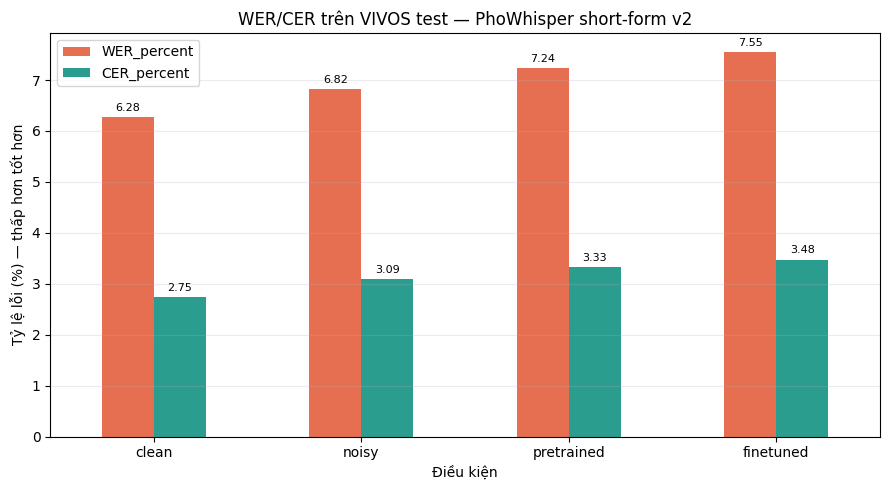

In [10]:
#@title 8. WER/CER PhoWhisper trên câu nguyên vẹn — short-form v2
if RUN_ASR:
    if not EVALUATE_UTTERANCES or not SAVE_ENHANCED:
        raise ValueError('Bật EVALUATE_UTTERANCES và SAVE_ENHANCED, rồi chạy Cell 7 trước.')
    import subprocess, sys, unicodedata, gc
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           'transformers>=4.45,<5', 'jiwer>=3,<4', 'accelerate'])
    import torch
    from transformers import pipeline
    from jiwer import process_words, process_characters

    # Cell 7 đã lưu enhanced WAV; nhường GPU cho PhoWhisper.
    for variable in ('training_model', 'pretrained_model', 'finetuned_model', 'models'):
        globals().pop(variable, None)
    keras.backend.clear_session()
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    torch_device = 0 if torch.cuda.is_available() else -1
    recognizer = pipeline('automatic-speech-recognition', model=ASR_MODEL,
                          device=torch_device,
                          torch_dtype=torch.float16 if torch_device == 0 else torch.float32)
    print('PhoWhisper device:', torch.cuda.get_device_name(0) if torch_device == 0 else 'CPU')

    def normalize_vietnamese(text):
        text = unicodedata.normalize('NFC', str(text)).lower()
        text = ''.join(c if unicodedata.category(c)[0] in 'LMN' or c.isspace() else ' '
                       for c in text)
        return ' '.join(text.split())

    refs = UTT_MANIFEST.set_index('filename').to_dict('index')
    if any(not str(refs[a.name].get('transcript', '')).strip() for a, b in UTTERANCE_PAIRS):
        raise ValueError('Thiếu transcript gốc: không tính WER/CER bằng chuỗi rỗng.')
    max_duration = max(sf.info(clean).frames / SR for _, clean in UTTERANCE_PAIRS)
    if max_duration >= 30:
        raise ValueError(f'Có câu dài {max_duration:.2f}s; giao thức short-form này yêu cầu <30s.')
    print(f'Số câu: {len(UTTERANCE_PAIRS)} | dài nhất: {max_duration:.2f}s')

    # Lỗi v1 do chunk/timestamp làm prediction lặp đến 400+ từ. VIVOS là câu ngắn,
    # nên giải mã short-form, không timestamp và không nối ngữ cảnh từ chunk trước.
    ASR_BATCH_SIZE = 8 if torch_device == 0 else 1
    GENERATE_KWARGS = {
        'language': 'vi', 'task': 'transcribe',
        'condition_on_prev_tokens': False,
        'do_sample': False, 'num_beams': 1,
        'max_new_tokens': 96,
    }
    protocol_data = {
        'version': 'short_v2', 'asr_model': ASR_MODEL,
        'return_timestamps': False, 'chunk_length_s': None,
        'generate_kwargs': GENERATE_KWARGS,
        'normalization': 'NFC-lowercase-keep-LMN-remove-punctuation',
    }
    protocol_hash = hashlib.sha256(
        json.dumps(protocol_data, sort_keys=True).encode('utf-8')).hexdigest()
    asr_dir = ACTIVE_EVAL / 'asr_fixed_v2'
    asr_dir.mkdir(parents=True, exist_ok=True)
    atomic_json(asr_dir / 'protocol.json', {**protocol_data, 'protocol_hash': protocol_hash})

    asr_rows = []
    for condition in ['clean', 'noisy', 'pretrained', 'finetuned']:
        # Cache mới: giữ nguyên asr_*.jsonl v1 làm bằng chứng chẩn đoán.
        cache = asr_dir / f'asr_{condition}.jsonl'
        existing = {}
        if cache.exists():
            for line in cache.read_text(encoding='utf-8').splitlines():
                try:
                    row = json.loads(line)
                    if row.get('protocol_hash') == protocol_hash:
                        existing[row['filename']] = row
                except json.JSONDecodeError:
                    pass
        with cache.open('w', encoding='utf-8') as f:
            for row in existing.values():
                f.write(json.dumps(row, ensure_ascii=False, allow_nan=False) + '\n')

        missing = [(noisy, clean) for noisy, clean in UTTERANCE_PAIRS
                   if noisy.name not in existing]
        with cache.open('a', encoding='utf-8') as f:
            for start in tqdm(range(0, len(missing), ASR_BATCH_SIZE),
                              desc=f'PhoWhisper-v2/{condition}'):
                chunk = missing[start:start + ASR_BATCH_SIZE]
                paths = [(clean if condition == 'clean' else noisy if condition == 'noisy'
                          else EVAL_CACHE / 'test_utterance' / condition / noisy.name)
                         for noisy, clean in chunk]
                inputs = [{'raw': read_audio(path), 'sampling_rate': SR} for path in paths]
                outputs = recognizer(inputs, batch_size=ASR_BATCH_SIZE,
                                     return_timestamps=False,
                                     generate_kwargs=GENERATE_KWARGS)
                for (noisy, _), output in zip(chunk, outputs):
                    name = noisy.name
                    prediction = output['text']
                    reference = normalize_vietnamese(refs[name]['transcript'])
                    hypothesis = normalize_vietnamese(prediction)
                    words = process_words(reference, hypothesis)
                    chars = process_characters(reference, hypothesis)
                    row = {
                        'condition': condition, 'filename': name, 'asr_model': ASR_MODEL,
                        'protocol_hash': protocol_hash, 'reference': reference,
                        'prediction': prediction, 'hypothesis': hypothesis,
                        'word_hits': words.hits, 'substitutions': words.substitutions,
                        'deletions': words.deletions, 'insertions': words.insertions,
                        'word_errors': words.substitutions + words.deletions + words.insertions,
                        'reference_words': words.hits + words.substitutions + words.deletions,
                        'char_errors': chars.substitutions + chars.deletions + chars.insertions,
                        'reference_chars': chars.hits + chars.substitutions + chars.deletions,
                        'reference_word_count': len(reference.split()),
                        'hypothesis_word_count': len(hypothesis.split()),
                        'snr_db_input': float(refs[name]['snr_db']),
                        'noise_environment': refs[name]['noise_environment'],
                    }
                    existing[name] = row
                    f.write(json.dumps(row, ensure_ascii=False, allow_nan=False) + '\n')
                    f.flush()
        asr_rows.extend(existing[noisy.name] for noisy, _ in UTTERANCE_PAIRS)

    asr_results = pd.DataFrame(asr_rows)
    totals = asr_results.groupby('condition')[[
        'word_hits', 'substitutions', 'deletions', 'insertions',
        'word_errors', 'reference_words', 'char_errors', 'reference_chars']].sum()
    totals['WER'] = totals['word_errors'] / totals['reference_words']
    totals['CER'] = totals['char_errors'] / totals['reference_chars']
    totals['WER_percent'] = 100 * totals['WER']
    totals['CER_percent'] = 100 * totals['CER']
    asr_results.to_csv(asr_dir / 'asr_per_utterance.csv', index=False)
    totals.to_csv(asr_dir / 'asr_summary.csv')
    # Tên rõ ràng ở evaluation root để các cell làm bảng đọc đúng bản v2.
    asr_results.to_csv(ACTIVE_EVAL / 'asr_per_utterance_fixed_v2.csv', index=False)
    totals.to_csv(ACTIVE_EVAL / 'asr_summary_fixed_v2.csv')
    display(totals[['word_hits', 'substitutions', 'deletions', 'insertions',
                    'WER_percent', 'CER_percent']].round(2))

    ratios = asr_results['hypothesis_word_count'] / asr_results['reference_word_count'].clip(lower=1)
    clean_wer = float(totals.loc['clean', 'WER'])
    print('Median hypothesis/reference word ratio:', round(float(ratios.median()), 3))
    if clean_wer > 1.0 or float(ratios.median()) > 3.0:
        print('CẢNH BÁO: kết quả v2 vẫn bất thường; chưa dùng WER/CER trong báo cáo.')
    else:
        print('Không còn dấu hiệu lặp hàng loạt. WER/CER thấp hơn tốt hơn.')

    import matplotlib.pyplot as plt
    chart = totals.loc[['clean', 'noisy', 'pretrained', 'finetuned'],
                       ['WER_percent', 'CER_percent']]
    ax = chart.plot(kind='bar', figsize=(9, 5), color=['#e76f51', '#2a9d8f'])
    ax.set(title='WER/CER trên VIVOS test — PhoWhisper short-form v2',
           xlabel='Điều kiện', ylabel='Tỷ lệ lỗi (%) — thấp hơn tốt hơn')
    ax.grid(axis='y', alpha=.25)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', padding=3, fontsize=8)
    plt.xticks(rotation=0); plt.tight_layout()
    plt.savefig(ACTIVE_EVAL / 'asr_comparison_fixed_v2.png', dpi=180, bbox_inches='tight')
    plt.show()
else:
    print('RUN_ASR=False: đã đánh giá chất lượng khử nhiễu; chưa chạy WER/CER.')


In [11]:
#@title 9. Lưu báo cáo, mã inference và ZIP kết quả trên Drive
import textwrap

inference_code = '''
from pathlib import Path
import sys
import soundfile as sf
from tensorflow import keras

# Chạy trong thư mục run hoặc sửa RUN thành đường dẫn trên Drive.
RUN = Path(__file__).resolve().parent
sys.path.insert(0, str(RUN / 'code'))
import dtln_colab_model
from dtln_colab_model import enhance

# Đổi thành pretrained/dtln_pretrained.keras để chạy model gốc.
model = keras.models.load_model(RUN / 'finetuned/dtln_finetuned_best.keras', compile=False)
audio, sr = sf.read('input.wav', dtype='float32')
assert sr == 16000 and audio.ndim == 1
enhanced = enhance(model, audio)
sf.write('enhanced.wav', enhanced, 16000, subtype='FLOAT')
'''
(RUN_DIR / 'inference_example.py').write_text(textwrap.dedent(inference_code).lstrip(), encoding='utf-8')
report = f'''# Fine-tune DTLN cho VIVOS

Pretrained: DTLN_norm_500h; upstream breizhn/DTLN commit {UPSTREAM_COMMIT}.
SHA256 pretrained gốc: {expected_sha}.
Best epoch: {best_record['epoch']}; val_loss: {best_record['val_loss']:.6f}.
SMOKE_TEST: {SMOKE_TEST}. Evaluation ID: {eval_id}.

- pretrained/: file H5 gốc, model .keras và weights .weights.h5 giữ riêng.
- finetuned/: model tốt nhất theo validation (.keras và .weights.h5).
- checkpoints/: full model/optimizer sau từng epoch; training_state.json phục vụ resume.
- code/: định nghĩa model tương thích Keras, nguồn và giấy phép MIT upstream.
- evaluation/{eval_id}/: CSV từng file, trung bình, theo SNR/môi trường và delta FT-pretrained.
- history.csv, training_curve.png, run_config.json, requirements_freeze.txt.

Import code/dtln_colab_model.py trước khi keras.models.load_model. Xem inference_example.py.
Model mong đợi mono 16 kHz. Hàm enhance thêm padding 384 mẫu và trả đúng chiều dài gốc.
Không chuẩn hóa gain riêng hoặc căn chỉnh theo clean khi đánh giá. WAV enhanced dùng FLOAT để tránh clip.
PESQ-WB/STOI/SI-SDR/SNR cao hơn tốt hơn. Lỗi PESQ/STOI được ghi ở cột error, count thể hiện mẫu hợp lệ.
Không khẳng định fine-tune tốt hơn trước khi xem kết quả; delta âm nghĩa là metric đó giảm.
WER/CER chỉ có khi RUN_ASR=True; baseline clean ASR giúp biết giới hạn của bộ nhận dạng.
Test hiện chỉ có hai môi trường DEMAND; không suy rộng kết quả sang mọi loại nhiễu.
Bootstrap theo file có thể đánh giá thấp bất định vì nhiều file dùng chung nguồn câu/noise.

Resume: giữ RUN_NAME, SMOKE_TEST, dữ liệu và cấu hình; chạy lại notebook với RESUME=True.
Khôi phục optimizer và epoch cuối đã ghi lên Drive. Epoch đang chạy dở phải chạy lại.
Patience của EarlyStopping/ReduceLROnPlateau được đếm lại khi mở phiên mới.
Để chạy đầy đủ sau smoke, đổi SMOKE_TEST=False; kết quả nằm ở thư mục run riêng.
'''
(RUN_DIR / 'README.md').write_text(report, encoding='utf-8')

# Archive enhanced một lần sau đánh giá; CSV được lưu liên tục trên Drive trong khi chạy.
if SAVE_ENHANCED:
    enhanced_zip = ACTIVE_EVAL / 'enhanced_audio.zip'
    local_wavs = sorted(EVAL_CACHE.rglob('*.wav'))
    with tempfile.NamedTemporaryFile(dir=ACTIVE_EVAL, suffix='.zip.part', delete=False) as f:
        tmp = Path(f.name)
    try:
        with zipfile.ZipFile(tmp, 'w', compression=zipfile.ZIP_STORED, allowZip64=True) as z:
            for wav in tqdm(local_wavs, desc='Lưu enhanced lên Drive'):
                z.write(wav, wav.relative_to(EVAL_CACHE).as_posix())
        os.replace(tmp, enhanced_zip)
    finally:
        tmp.unlink(missing_ok=True)

# Bundle gọn gồm hai model, báo cáo và code; checkpoint vẫn được giữ riêng trên Drive.
bundle = RUN_DIR / 'dtln_models_and_reports.zip'
include = [p for folder in [PRE_DIR, FT_DIR, CODE_DIR, ACTIVE_EVAL]
           for p in folder.rglob('*') if p.is_file() and p.name != 'enhanced_audio.zip']
include += [RUN_DIR / name for name in ['README.md', 'inference_example.py', 'history.csv',
            'training_curve.png', 'run_config.json', 'training_state.json', 'requirements_freeze.txt']]
with tempfile.NamedTemporaryFile(dir=RUN_DIR, suffix='.zip.part', delete=False) as f:
    tmp = Path(f.name)
try:
    with zipfile.ZipFile(tmp, 'w', compression=zipfile.ZIP_DEFLATED, allowZip64=True) as z:
        for p in include:
            if p.is_file():
                z.write(p, p.relative_to(RUN_DIR).as_posix())
    os.replace(tmp, bundle)
finally:
    tmp.unlink(missing_ok=True)
print('Đã lưu hai model, checkpoint và báo cáo tại:', RUN_DIR)
print('Gói model + báo cáo:', bundle)
print('Báo cáo test:', ACTIVE_EVAL / 'test_summary.csv')


Lưu enhanced lên Drive:   0%|          | 0/5520 [00:00<?, ?it/s]

Đã lưu hai model, checkpoint và báo cáo tại: /content/drive/MyDrive/dataset/dtln_models/dtln_vivos_ft_v1
Gói model + báo cáo: /content/drive/MyDrive/dataset/dtln_models/dtln_vivos_ft_v1/dtln_models_and_reports.zip
Báo cáo test: /content/drive/MyDrive/dataset/dtln_models/dtln_vivos_ft_v1/evaluation/31d0c68bf81ed587/test_summary.csv


## File được giữ trên Drive

```text
dtln_vivos_ft_v1/
├── pretrained/  # H5 gốc, dtln_pretrained.keras, dtln_pretrained.weights.h5
├── finetuned/   # dtln_finetuned_best.keras, .weights.h5, best_checkpoint.json
├── checkpoints/ # epoch_0001.keras ... gồm optimizer để resume
├── evaluation/<eval_id>/
│   ├── test_metrics_per_file.csv
│   ├── test_summary.csv
│   ├── test_by_snr.csv
│   ├── test_by_environment.csv
│   ├── paired_improvements.csv
│   ├── comparison_by_snr.png
│   ├── enhanced_audio.zip
│   └── asr_summary.csv  # khi RUN_ASR=True
├── code/  # định nghĩa model, nguồn upstream và LICENSE
├── dtln_models_and_reports.zip
├── history.csv / training_curve.png / run_config.json
└── inference_example.py / README.md / requirements_freeze.txt
```

Import `code/dtln_colab_model.py` trước khi load `.keras`. Ví dụ inference nằm trong
`inference_example.py`. Khi so sánh ASR, dùng transcript câu nguyên vẹn từ
`manifest_utterance.csv`, không dùng transcript đầy đủ để chấm cửa sổ 4 giây bị cắt.

Nguồn DTLN: https://github.com/breizhn/DTLN (MIT). Trọng số lấy từ commit đã ghim,
được kiểm tra SHA256; định nghĩa lớp mới giữ nguyên phép tính của kiến trúc gốc.
